# PlantVillage → Bangladesh: full-model fine-tuning

The complete PlantVillage binary CNN, including its Healthy/Unhealthy head, is fine-tuned on Bangladesh development images. This notebook reviews saved results on CPU. The reused holdout is exploratory; it is not new independent evidence.

In [1]:
from pathlib import Path
import json, sys
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if not (ROOT/"model.py").exists():
    ROOT=ROOT/"cnn-plant-disease-detection"
sys.path.insert(0,str(ROOT))
OUT=ROOT/"bangladesh_finetuned_outputs"
metrics=json.loads((OUT/"test_metrics.json").read_text(encoding="utf-8"))
record=json.loads((OUT/"experiment.json").read_text(encoding="utf-8"))
print("Stages:", *record["stages"], sep="\n")
print("Selected:", metrics["selected_initialization"])
print("GPU used for training:",record["gpu"])

Stages:
Existing PlantVillage binary model trained on 14528 development images; 3632 test images excluded from training
Initialize every fold and final fit independently from that exact full checkpoint; retain all layers including the binary head
Fine-tune all parameters and BatchNorm statistics using only eligible Bangladesh development images
Selected: full_finetune
GPU used for training: NVIDIA GeForce RTX 4070 Ti SUPER


Classes: ['Healthy', 'Unhealthy']
Parameters: 939874
Original binary head retained: True


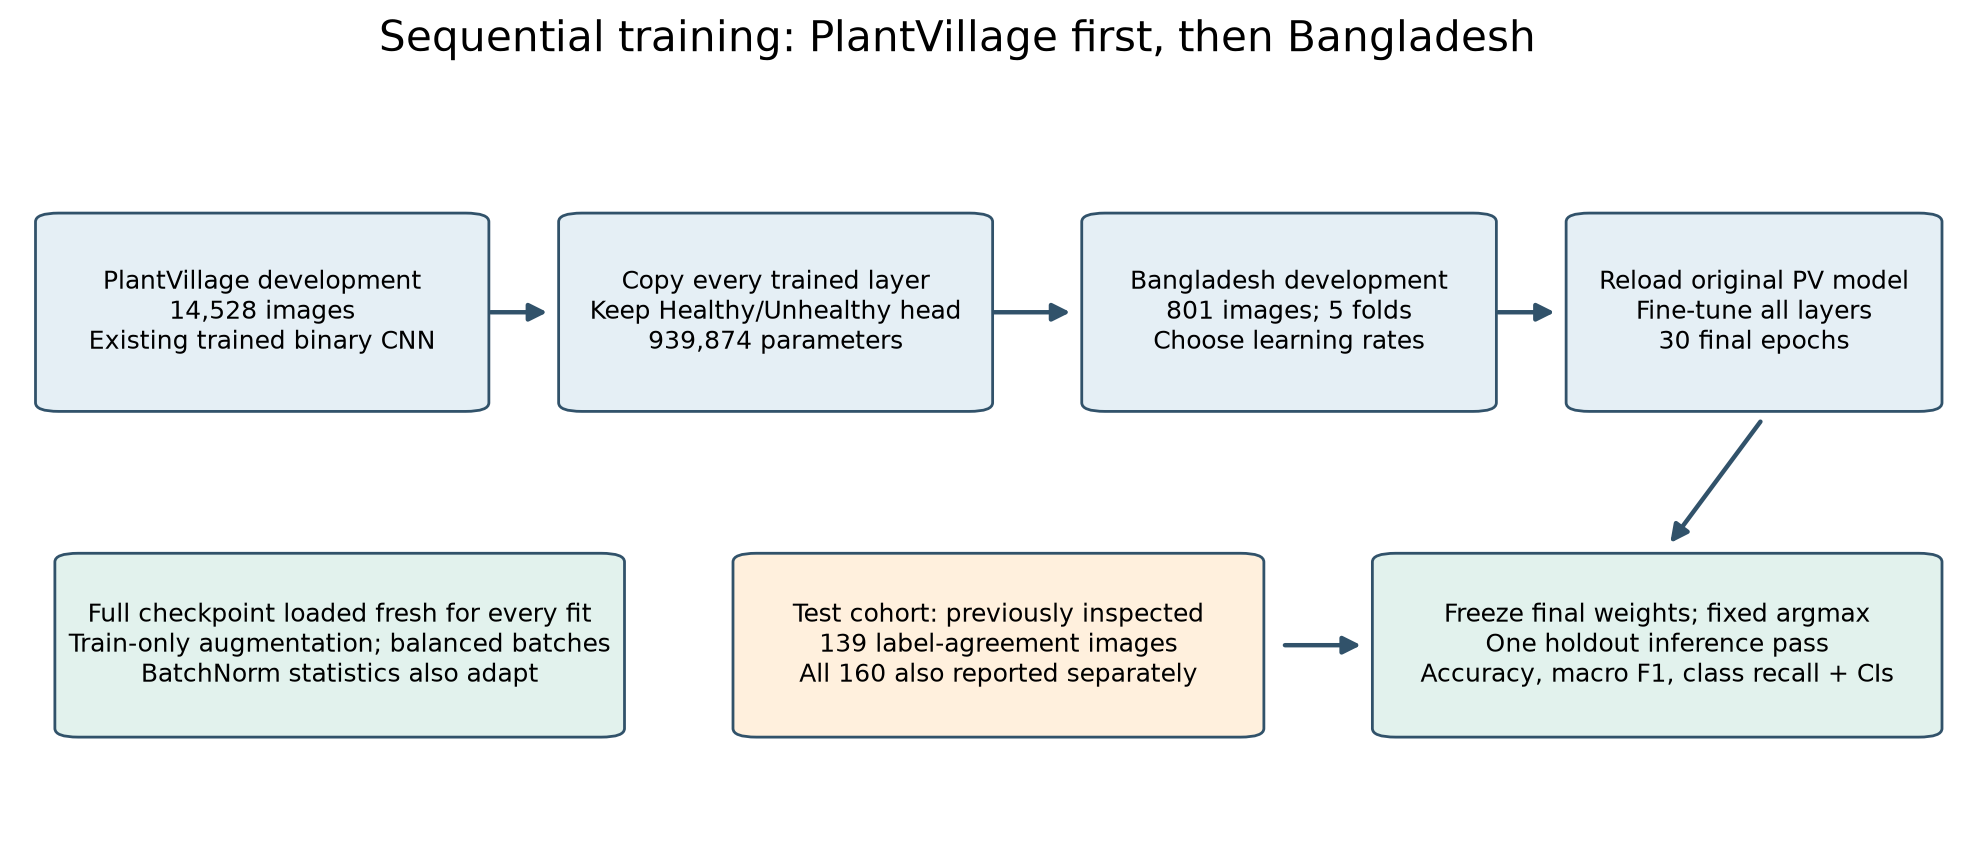

In [2]:
import torch
from model import TomatoCNN
checkpoint=torch.load(OUT/"tomato_cnn_finetuned.pt",map_location="cpu",weights_only=True)
model=TomatoCNN(checkpoint["channels"],2)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
print("Classes:",checkpoint["classes"])
print("Parameters:",sum(p.numel() for p in model.parameters()))
print("Original binary head retained:",checkpoint["binary_head_retained"])
display(Image(filename=str(ROOT/"figures/bangladesh_finetuned_workflow.png"),width=1100))

full_finetune CV balanced accuracy: 75.89% CV macro F1: 76.24%
differential_finetune CV balanced accuracy: 63.19% CV macro F1: 61.99%


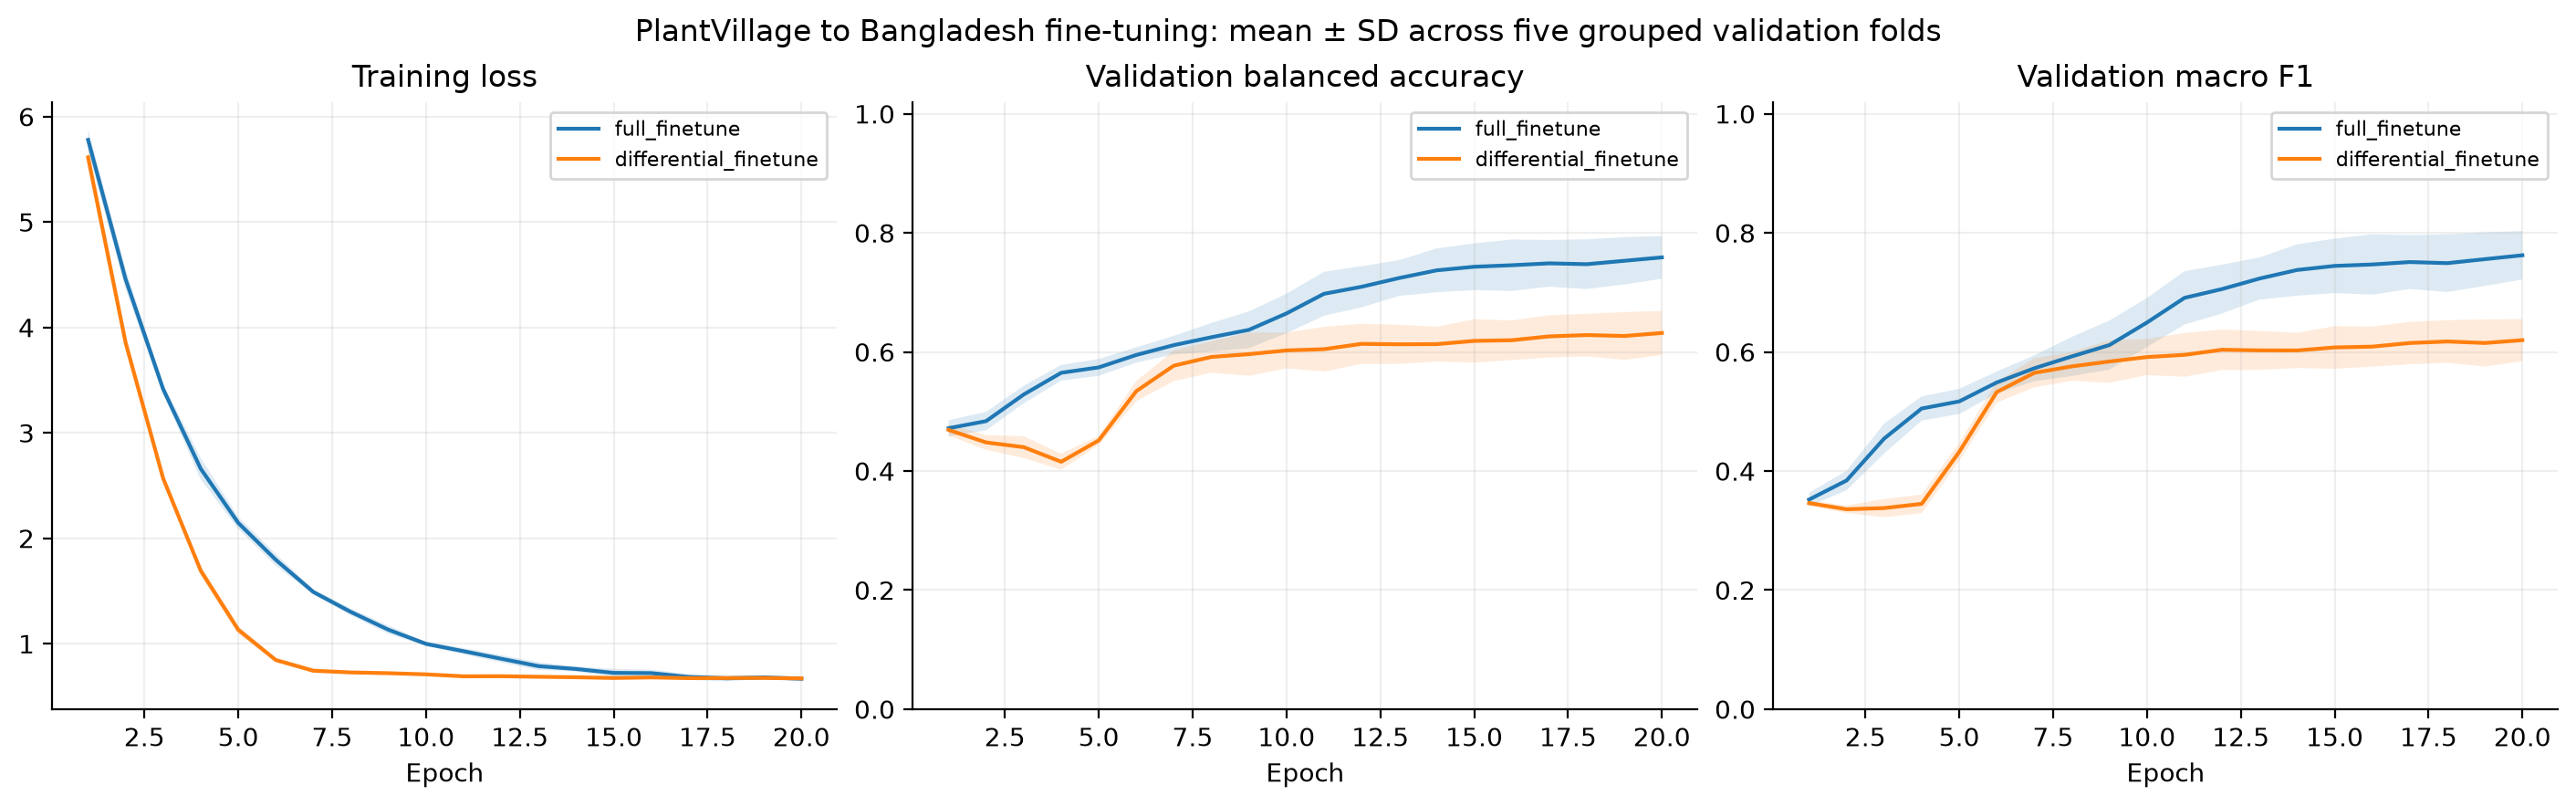

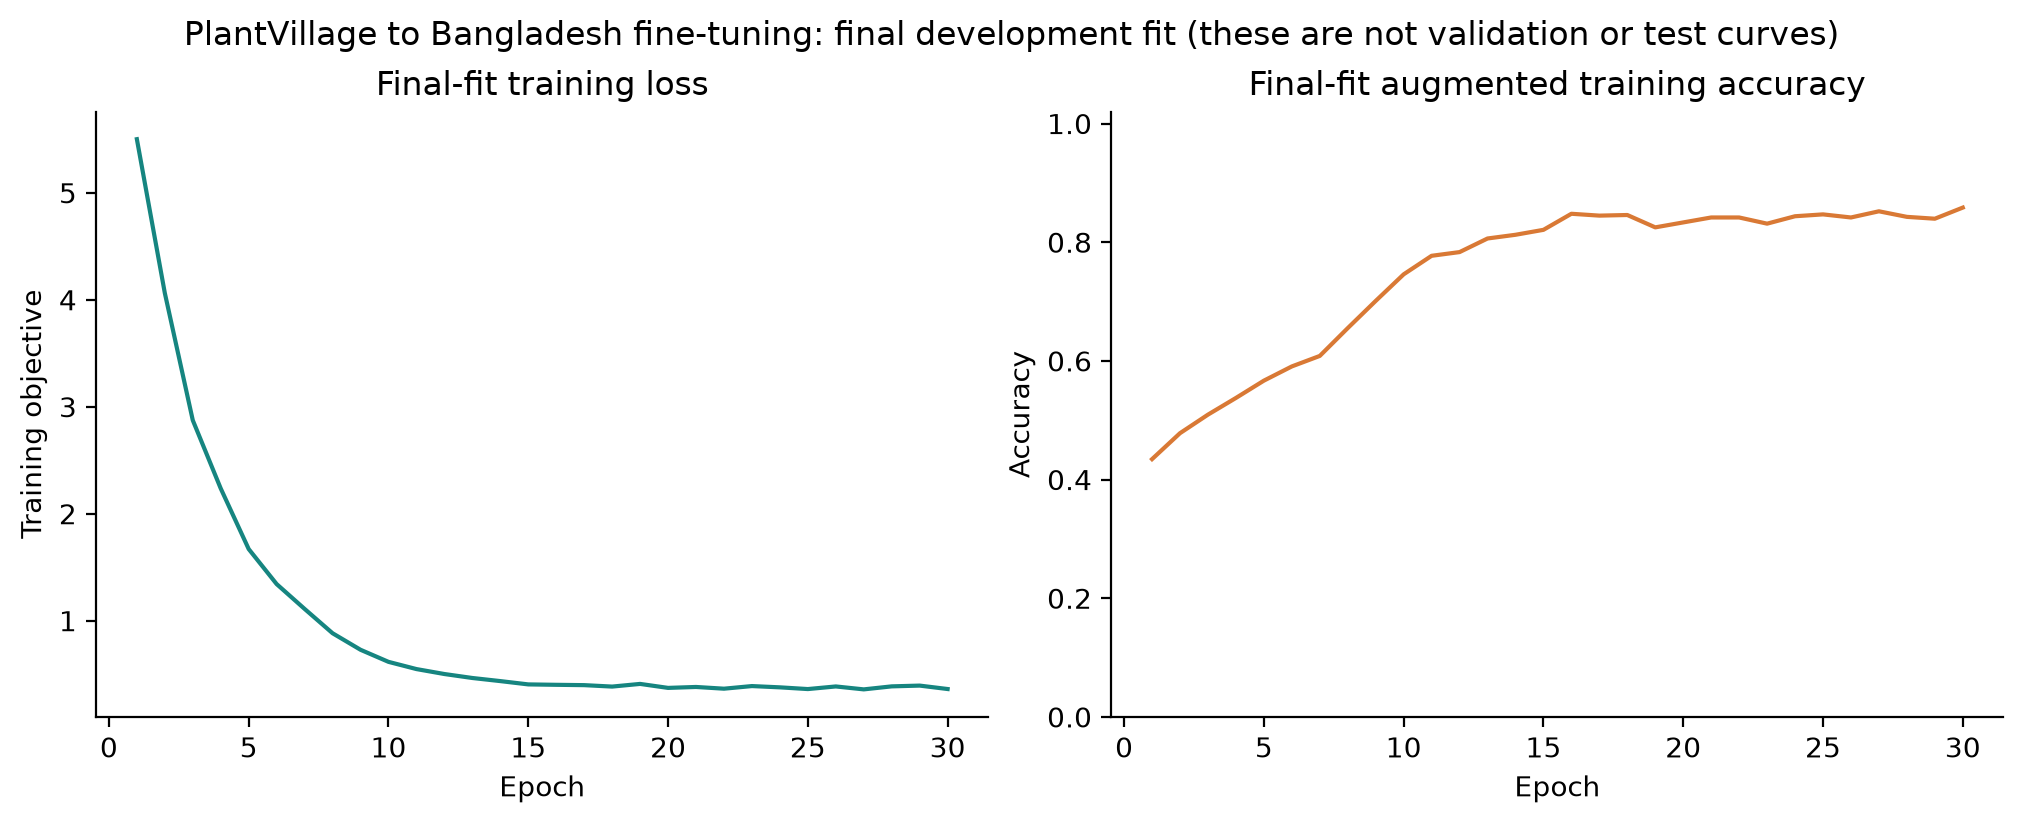

In [3]:
cv=json.loads((OUT/"cross_validation.json").read_text(encoding="utf-8"))
for recipe,scores in cv.items():
    print(recipe, "CV balanced accuracy:",f"{scores["mean_balanced_accuracy"]:.2%}", "CV macro F1:",f"{scores["mean_macro_f1"]:.2%}")
display(Image(filename=str(ROOT/"figures/bangladesh_finetuned_cv_learning_curves.png"),width=1100))
display(Image(filename=str(ROOT/"figures/bangladesh_finetuned_final_training_curves.png"),width=1000))

accuracy 0.8777
balanced_accuracy 0.8582
macro_f1 0.8689
precision_unhealthy 0.8316
recall_sensitivity_unhealthy 0.9875
specificity_healthy 0.7288
roc_auc 0.9532
Reference rows / prediction columns: [[43, 16], [1, 79]]


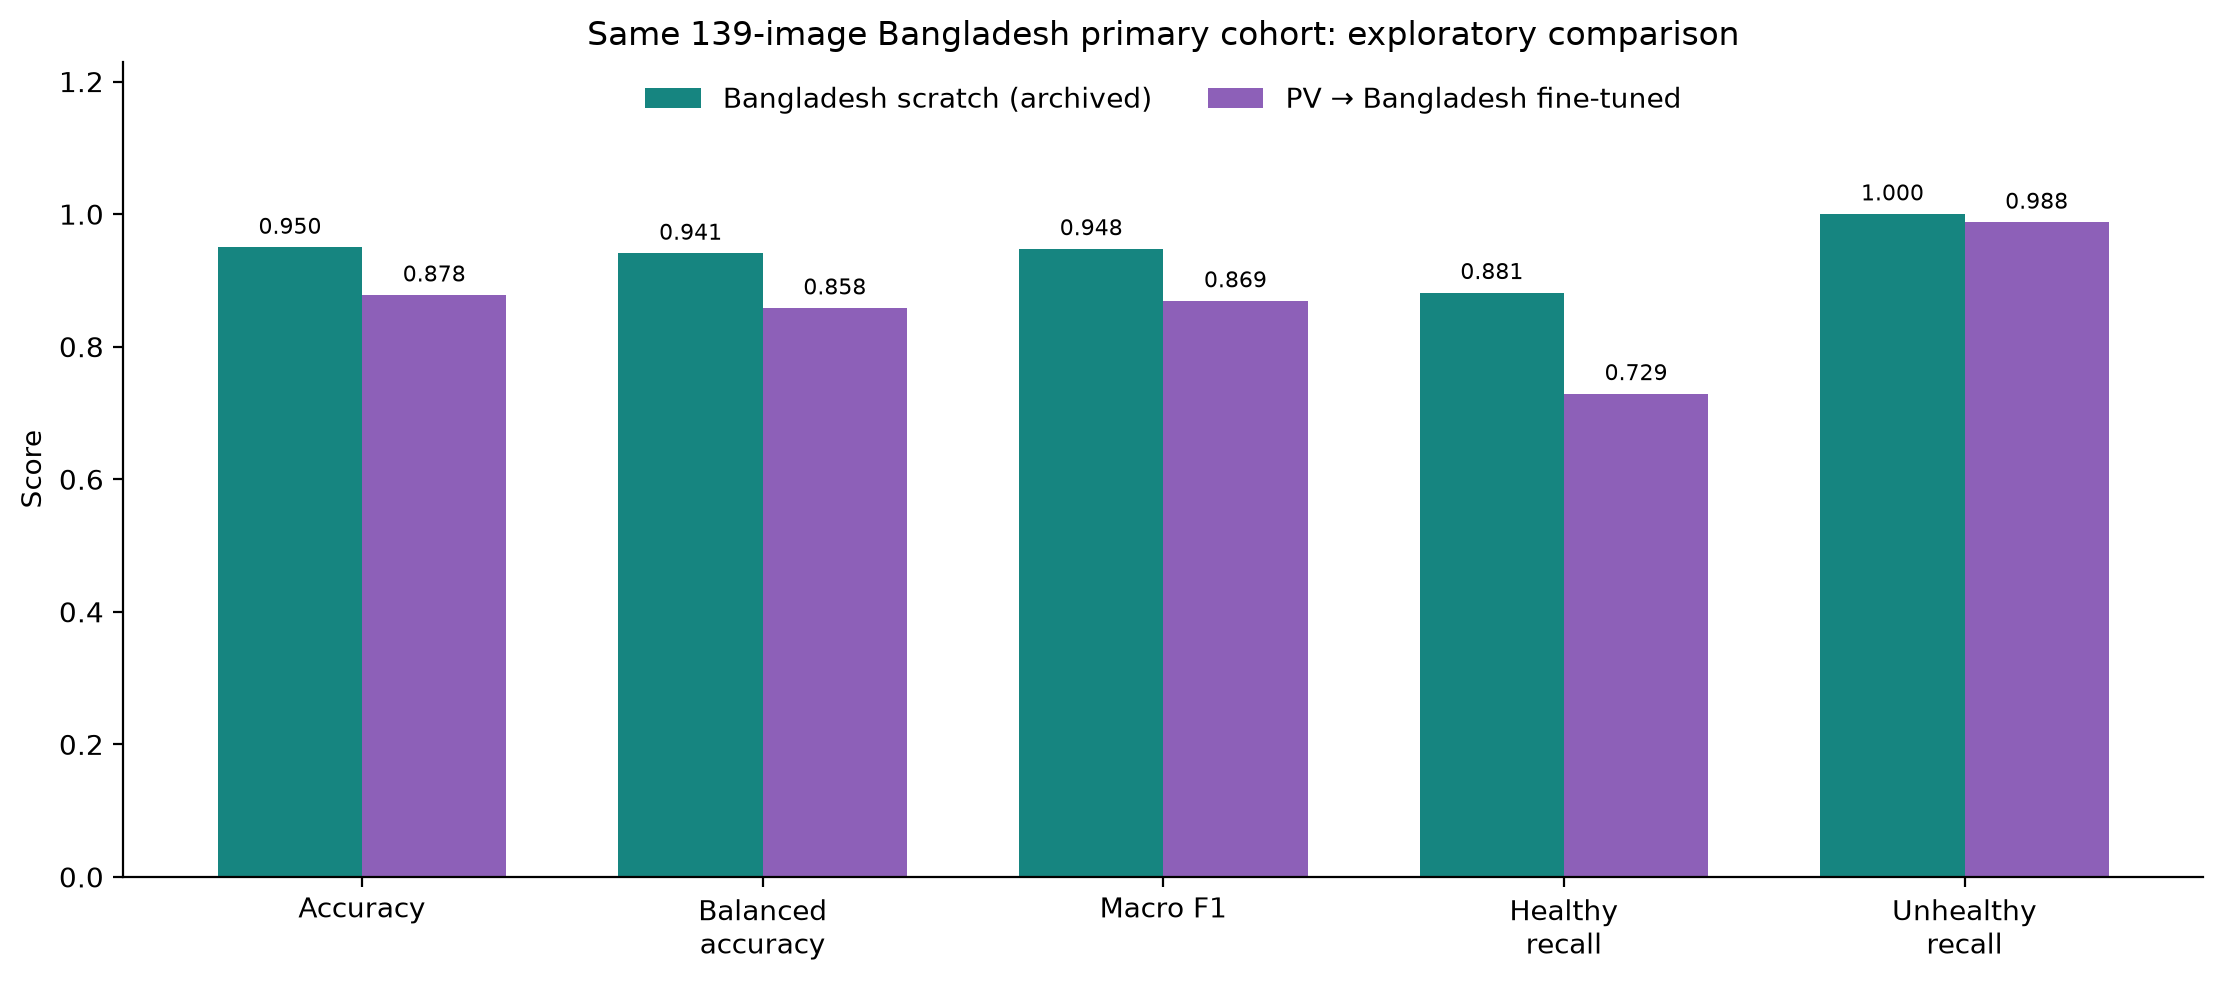

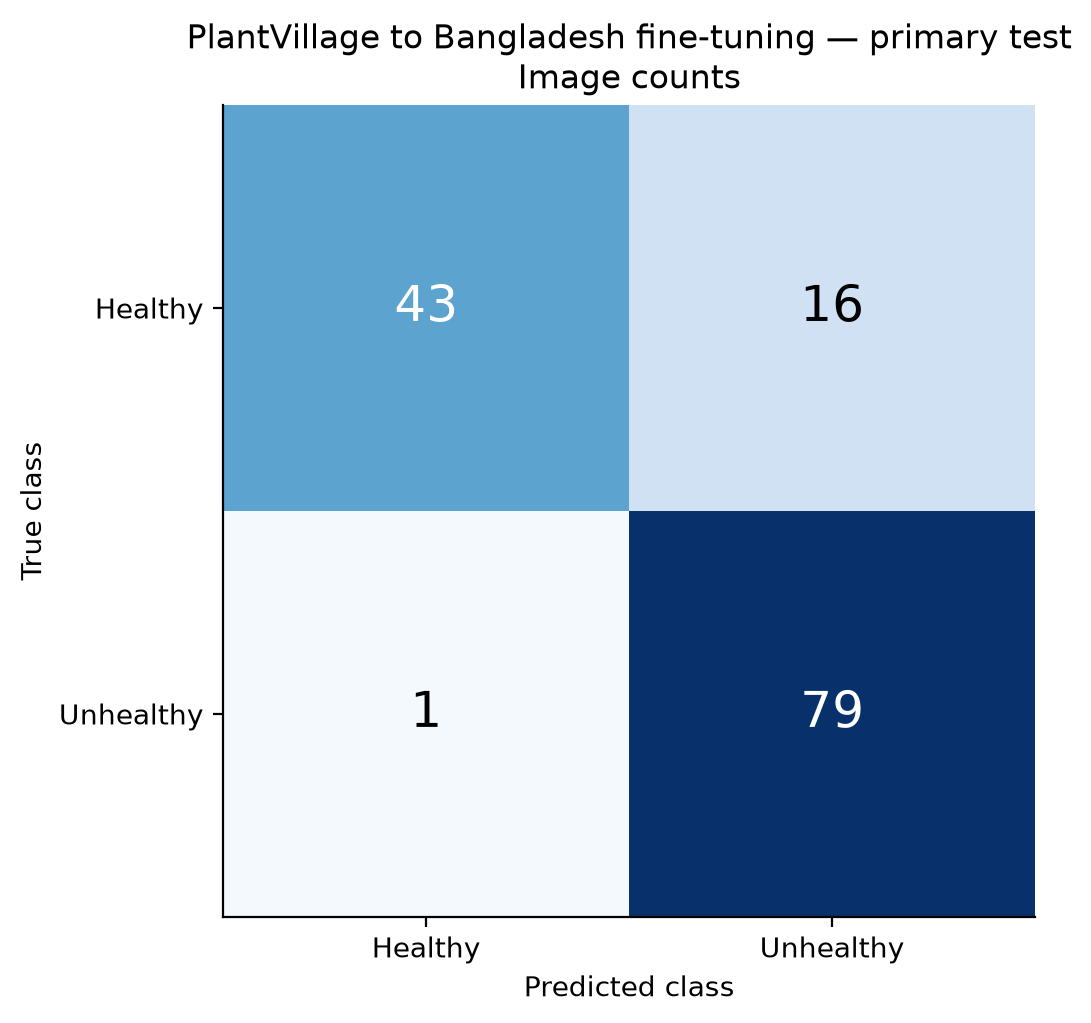

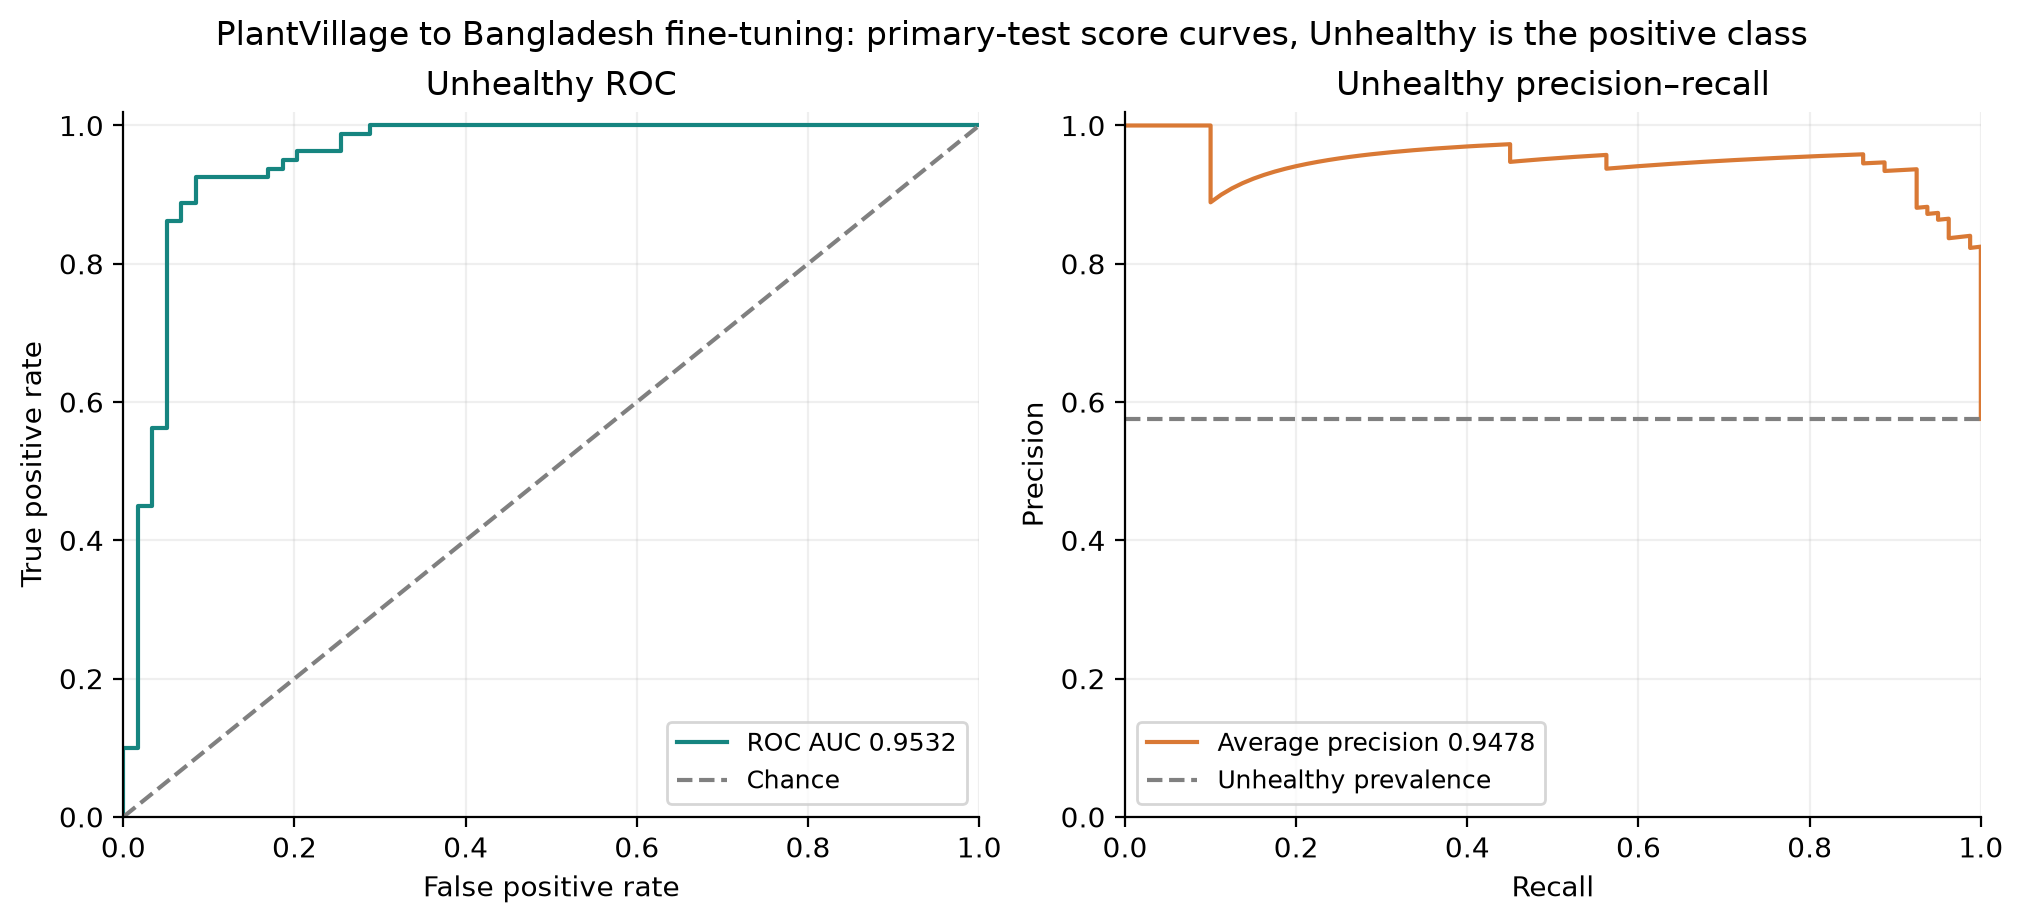

In [4]:
for key in ("accuracy","balanced_accuracy","macro_f1","precision_unhealthy","recall_sensitivity_unhealthy","specificity_healthy","roc_auc"):
    print(key,f"{metrics[key]:.4f}")
print("Reference rows / prediction columns:",metrics["confusion_matrix"])
display(Image(filename=str(ROOT/"figures/bangladesh_finetuned_comparison.png"),width=1000))
display(Image(filename=str(ROOT/"figures/bangladesh_finetuned_confusion_counts.png"),width=650))
display(Image(filename=str(ROOT/"figures/bangladesh_finetuned_roc_precision_recall.png"),width=1000))

Full holdout contains 21 conflicting filename/annotation labels.
accuracy 79.38%
balanced_accuracy 79.38%
macro_f1 78.57%
specificity_healthy 60.00%
recall_sensitivity_unhealthy 98.75%


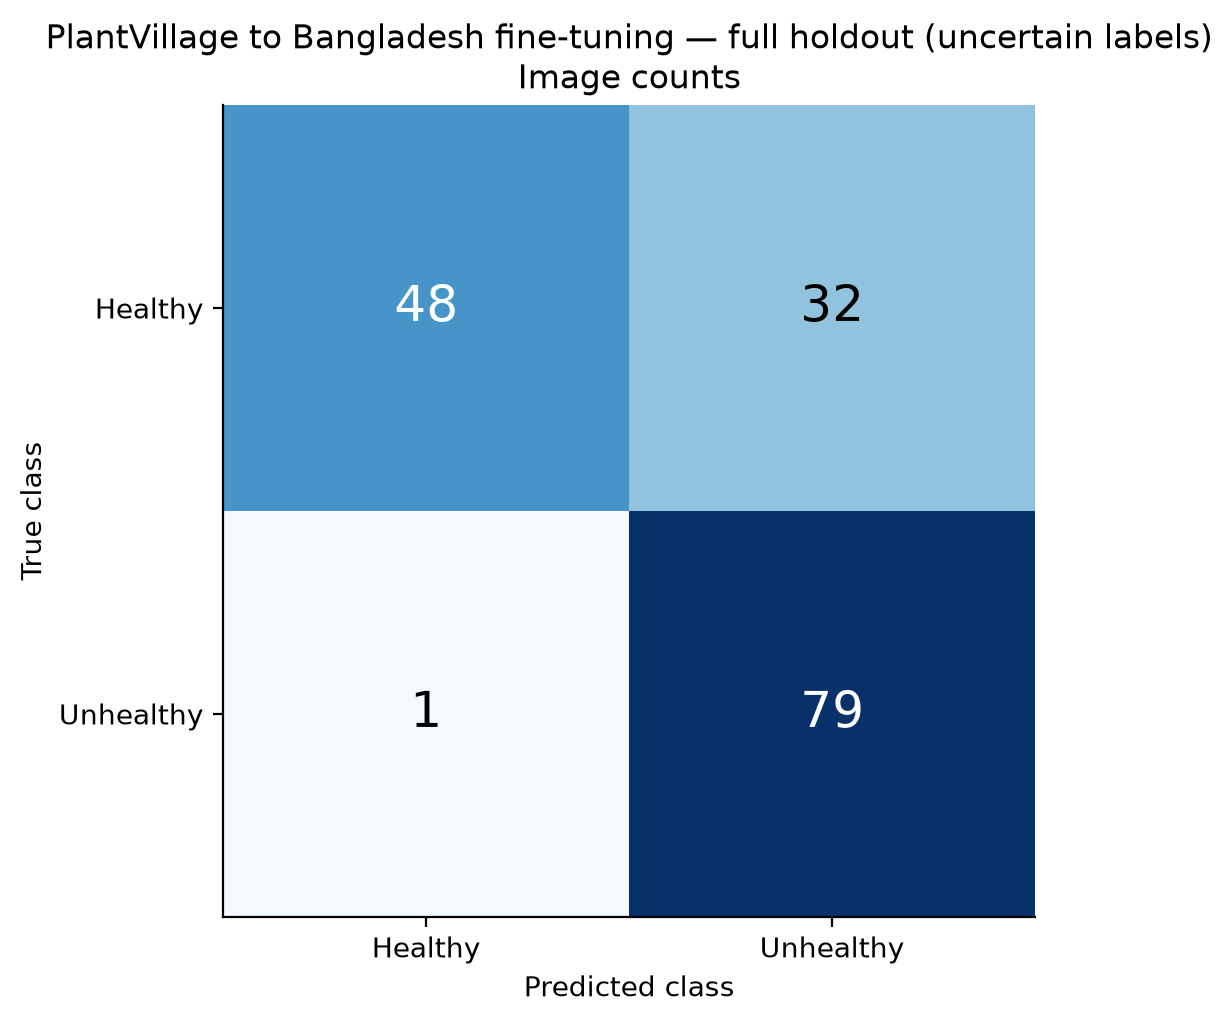

{'passed': True, 'dataset': 'bangladesh-finetuned', 'binary_checkpoint_loaded_on_cpu': True, 'checkpoint_sha256': 'bab06f5eeb3d975d53dffd457c8a1d2ee35cc2c50c26097306f3d8a1fd8df72a', 'test_csv_confusion_metrics_independently_verified': True, 'all_class_precision_recall_f1_verified': True, 'split_and_cv_groups_pixels_files_disjoint': True, 'cv_summaries_and_history_lengths_checked': True, 'test_inference_performed': False, 'full_pretrained_checkpoint_provenance_checked': True, 'every_training_draw_checked_against_development_folds': True, 'all_batches_class_balanced': True}


In [5]:
full=json.loads((OUT/"released_holdout_metrics.json").read_text(encoding="utf-8"))
print("Full holdout contains 21 conflicting filename/annotation labels.")
for key in ("accuracy","balanced_accuracy","macro_f1","specificity_healthy","recall_sensitivity_unhealthy"):
    print(key,f"{full[key]:.2%}")
display(Image(filename=str(ROOT/"figures/bangladesh_finetuned_full_holdout_confusion_counts.png"),width=650))
print(json.loads((OUT/"verification.json").read_text(encoding="utf-8")))

## Try the model

```powershell
python predict.py "C:\path\to\leaf.jpg" --dataset bangladesh-finetuned
```

The model predicts tomato leaf health, without naming a disease. See FINETUNING_RESULTS.md for the comparison and limitations.